In [1]:
# BigMart Sales: EDA, one feature at a time
# Goal: predict Item_Outlet_Sales for every (product, store) pair. Score: RMSE (smaller is better).

import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# 1. Whole dataset

# works whether Jupyter runs from the notebooks folder or from the project folder
root = '..' if os.path.exists('../dataset') else '.'
os.makedirs(root + '/outputs/figures', exist_ok=True)

df = pd.read_csv(root + '/dataset/train_v9rqX0R.csv')
print('Rows and columns:', df.shape)

Rows and columns: (8523, 12)


In [3]:
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


In [5]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [6]:
duplicates = df.duplicated().sum()
print('Duplicate rows:', duplicates, '=', round(duplicates / len(df) * 100, 2), '%')
print()
print(df.isnull().sum())
print()
print(df.isnull().sum() / len(df) * 100)

# Item_Weight (17.17%) and Outlet_Size (28.28%) are missing. Each is handled in its own section below.

Duplicate rows: 0 = 0.0 %

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

Item_Identifier               0.000000
Item_Weight                  17.165317
Item_Fat_Content              0.000000
Item_Visibility               0.000000
Item_Type                     0.000000
Item_MRP                      0.000000
Outlet_Identifier             0.000000
Outlet_Establishment_Year     0.000000
Outlet_Size                  28.276428
Outlet_Location_Type          0.000000
Outlet_Type                   0.000000
Item_Outlet_Sales             0.000000
dtype: float64


In [7]:
# 2. Target: Item_Outlet_Sales

print(df['Item_Outlet_Sales'].describe())
print('Skewness:', df['Item_Outlet_Sales'].skew())

# The mean (2181) is above the median (1794): sales are skewed to the right.

Q1 = df['Item_Outlet_Sales'].quantile(0.25)
Q3 = df['Item_Outlet_Sales'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['Item_Outlet_Sales'] < lower_bound) | (df['Item_Outlet_Sales'] > upper_bound)]

print('Lower Bound:', lower_bound)
print('Upper Bound:', upper_bound)
print('Number of outliers:', len(outliers))
print('Percent of outliers:', len(outliers) / len(df) * 100)

# 186 outliers (2.18%), all on the high side. They are real big sales, so we keep them.

count     8523.000000
mean      2181.288914
std       1706.499616
min         33.290000
25%        834.247400
50%       1794.331000
75%       3101.296400
max      13086.964800
Name: Item_Outlet_Sales, dtype: float64
Skewness: 1.1775306028542794
Lower Bound: -2566.3261
Upper Bound: 6501.8699
Number of outliers: 186
Percent of outliers: 2.1823301654347063


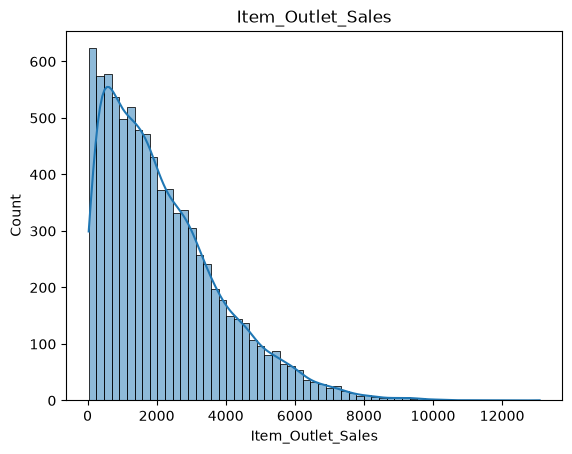

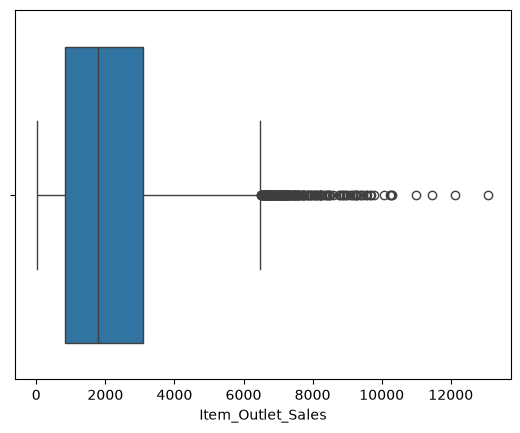

In [8]:
sns.histplot(df['Item_Outlet_Sales'], kde=True)
plt.title('Item_Outlet_Sales')
plt.savefig(root + '/outputs/figures/sales_histogram.png', dpi=120, bbox_inches='tight')
plt.show()

sns.boxplot(x=df['Item_Outlet_Sales'])
plt.show()

# Most sales are small and a few are very large.

In [9]:
# 3. Item_Identifier

print('Different items:', df['Item_Identifier'].nunique())
print(df['Item_Identifier'].value_counts().describe())

# first two letters of the id: FD (food), DR (drink), NC (non-consumable)
df['Item_Kind'] = df['Item_Identifier'].str[:2]
print(df['Item_Kind'].value_counts())
print(df['Item_Kind'].value_counts() / len(df) * 100)
print(df.groupby('Item_Kind')['Item_Outlet_Sales'].mean())

# Each item is sold in several outlets. Average sales differ only a little between the three kinds.

# the number at the end of the id (FDA15 -> 15)
df['id_num'] = df['Item_Identifier'].str[3:].astype(int)
print(df['id_num'].describe())

Different items: 1559
count    1559.000000
mean        5.466966
std         1.528516
min         1.000000
25%         4.000000
50%         5.000000
75%         6.500000
max        10.000000
Name: count, dtype: float64
Item_Kind
FD    6125
NC    1599
DR     799
Name: count, dtype: int64
Item_Kind
FD    71.864367
NC    18.761000
DR     9.374633
Name: count, dtype: float64
Item_Kind
DR    1997.333337
FD    2215.354223
NC    2142.721364
Name: Item_Outlet_Sales, dtype: float64
count    8523.000000
mean       30.327350
std        17.244758
min         1.000000
25%        15.000000
50%        30.000000
75%        45.000000
max        60.000000
Name: id_num, dtype: float64


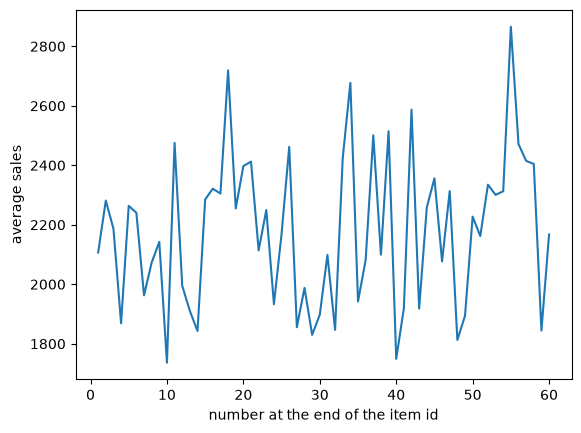

[np.float64(0.07), np.float64(0.06), np.float64(0.25), np.float64(-0.25), np.float64(0.11), np.float64(-0.18), np.float64(-0.34), np.float64(0.14), np.float64(-0.21), np.float64(-0.11), np.float64(0.04), np.float64(-0.23), np.float64(0.14), np.float64(-0.14), np.float64(-0.17), np.float64(0.3), np.float64(-0.02), np.float64(0.19), np.float64(0.32), np.float64(-0.09), np.float64(0.26), np.float64(0.03), np.float64(-0.12), np.float64(0.03), np.float64(-0.28), np.float64(-0.13), np.float64(-0.12), np.float64(-0.1), np.float64(-0.1), np.float64(-0.16)]


In [10]:
avg_by_id = df.groupby('id_num')['Item_Outlet_Sales'].mean()
avg_by_id.plot()
plt.xlabel('number at the end of the item id')
plt.ylabel('average sales')
plt.savefig(root + '/outputs/figures/sales_by_id_number.png', dpi=120, bbox_inches='tight')
plt.show()

# The average is bumpy, not flat, so the id number carries a little information.

# does the bumpy pattern repeat? correlation of the average with itself shifted by 1 to 30 ids
print([round(avg_by_id.autocorr(lag), 2) for lag in range(1, 31)])

# Lag 19 is the highest (0.32), but lags 16 and 3 are almost as high: a repeat of about 20 ids is only weakly supported.

count    7060.000000
mean       12.857645
std         4.643456
min         4.555000
25%         8.773750
50%        12.600000
75%        16.850000
max        21.350000
Name: Item_Weight, dtype: float64
Missing: 1463 = 17.17 %
Outlet_Identifier
OUT027    935
OUT019    528
Name: count, dtype: int64
Correlation with sales: 0.014122739280056468
Missing after filling: 0


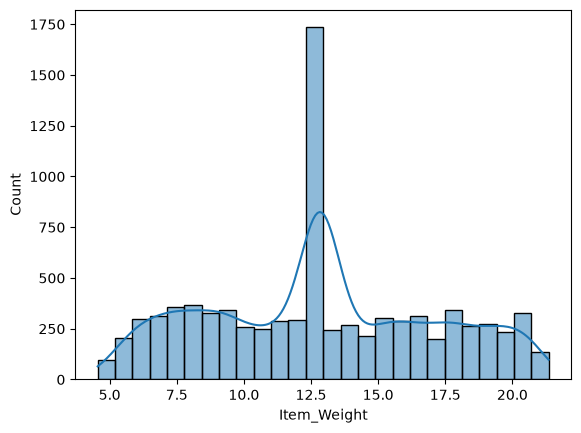

In [11]:
# 4. Item_Weight

print(df['Item_Weight'].describe())
missing = df['Item_Weight'].isnull().sum()
print('Missing:', missing, '=', round(missing / len(df) * 100, 2), '%')
print(df.loc[df['Item_Weight'].isnull(), 'Outlet_Identifier'].value_counts())

# The weight is missing only in OUT027 and OUT019, not at random.

print('Correlation with sales:', df['Item_Weight'].corr(df['Item_Outlet_Sales']))

# No link with sales.

df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Weight'].mean())
print('Missing after filling:', df['Item_Weight'].isnull().sum())

# Filled with the mean. The column is not used for prediction, so this is only for tidiness.

sns.histplot(df['Item_Weight'], kde=True)
plt.show()

In [12]:
# 5. Item_Fat_Content

print(df['Item_Fat_Content'].value_counts())
print(df['Item_Fat_Content'].value_counts() / len(df) * 100)

# merge the different spellings of the same two labels
df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})
print(df['Item_Fat_Content'].value_counts())
print(df['Item_Fat_Content'].value_counts() / len(df) * 100)
print(df.groupby('Item_Fat_Content')['Item_Outlet_Sales'].mean())

# Low Fat and Regular sell about the same.

Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64
Item_Fat_Content
Low Fat    59.709023
Regular    33.896515
LF          3.707615
reg         1.372756
low fat     1.314091
Name: count, dtype: float64
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64
Item_Fat_Content
Low Fat    64.730729
Regular    35.269271
Name: count, dtype: float64
Item_Fat_Content
Low Fat    2157.711534
Regular    2224.561170
Name: Item_Outlet_Sales, dtype: float64


count    8523.000000
mean        0.066132
std         0.051598
min         0.000000
25%         0.026989
50%         0.053931
75%         0.094585
max         0.328391
Name: Item_Visibility, dtype: float64
Visibility_cat
non-zero    7997
zero         526
Name: count, dtype: int64
Visibility_cat
non-zero    93.828464
zero         6.171536
Name: count, dtype: float64


Correlation with sales: -0.12862461222077026
Outlet_Type
Grocery Store        0.104862
Supermarket Type1    0.060723
Supermarket Type2    0.061014
Supermarket Type3    0.058615
Name: Item_Visibility, dtype: float64


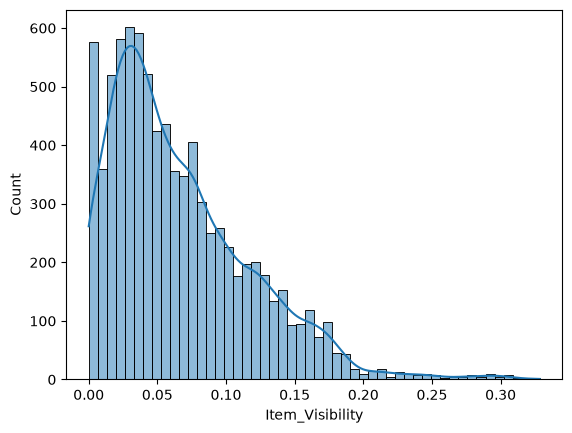

In [13]:
# 6. Item_Visibility

print(df['Item_Visibility'].describe())

df['Visibility_cat'] = np.where(df['Item_Visibility'] == 0, 'zero', 'non-zero')
print(df['Visibility_cat'].value_counts())
print(df['Visibility_cat'].value_counts() / len(df) * 100)

# 526 rows (6.17%) have visibility 0, which is not possible on a shelf. The column is not used.

print('Correlation with sales:', df['Item_Visibility'].corr(df['Item_Outlet_Sales']))
print(df.groupby('Outlet_Type')['Item_Visibility'].mean())

# A weak negative link. Grocery stores have larger visibility and sell less, so it comes from the store type.

sns.histplot(df['Item_Visibility'], kde=True)
plt.show()

In [14]:
# 7. Item_Type

print(df['Item_Type'].value_counts())
print(df['Item_Type'].value_counts() / len(df) * 100)
print(df.groupby('Item_Type')['Item_Outlet_Sales'].mean().sort_values())

# Average sales differ only a little between item types.

Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64
Item_Type
Fruits and Vegetables    14.455004
Snack Foods              14.079549
Household                10.676992
Frozen Foods             10.043412
Dairy                     8.001877
Canned                    7.614690
Baking Goods              7.602957
Health and Hygiene        6.101138
Soft Drinks               5.221166
Meat                      4.986507
Breads                    2.944972
Hard Drinks               2.510853
Others                    1.982870
Starchy Foods      

In [15]:
# 8. Item_MRP

print(df['Item_MRP'].describe())
print('Correlation with sales:', df['Item_MRP'].corr(df['Item_Outlet_Sales']))

# The only clear link with sales.

Q1 = df['Item_MRP'].quantile(0.25)
Q3 = df['Item_MRP'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['Item_MRP'] < lower_bound) | (df['Item_MRP'] > upper_bound)]

print('Lower Bound:', lower_bound)
print('Upper Bound:', upper_bound)
print('Number of outliers:', len(outliers))
print('Percent of outliers:', len(outliers) / len(df) * 100)

# MRP has no outliers.

count    8523.000000
mean      140.992782
std        62.275067
min        31.290000
25%        93.826500
50%       143.012800
75%       185.643700
max       266.888400
Name: Item_MRP, dtype: float64
Correlation with sales: 0.5675744466569194
Lower Bound: -43.8993
Upper Bound: 323.3695
Number of outliers: 0
Percent of outliers: 0.0


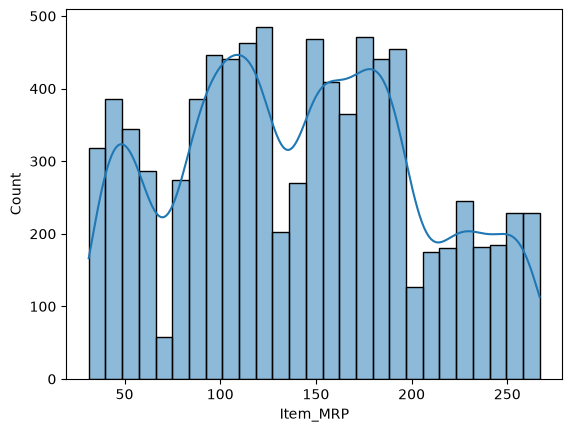

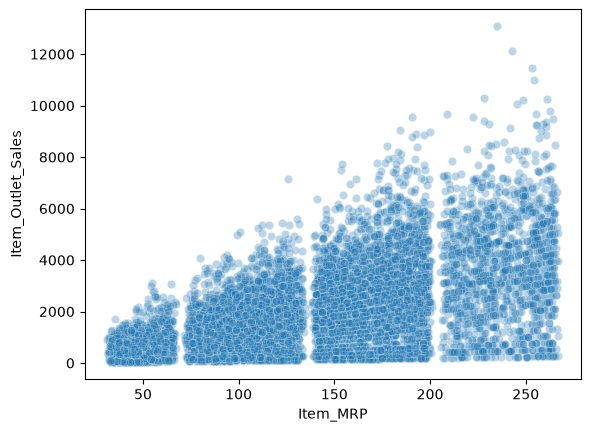

In [16]:
sns.histplot(df['Item_MRP'], kde=True)
plt.show()

# Several bumps between 31 and 267: prices come in clusters.

sns.scatterplot(x='Item_MRP', y='Item_Outlet_Sales', data=df, alpha=0.3)
plt.savefig(root + '/outputs/figures/sales_vs_mrp.png', dpi=120, bbox_inches='tight')
plt.show()

# Sales rise with MRP and spread out as the price grows.

In [17]:
# 9. Outlet_Identifier

print(df['Outlet_Identifier'].value_counts())
print(df['Outlet_Identifier'].value_counts() / len(df) * 100)
print(df.groupby('Outlet_Identifier')['Item_Outlet_Sales'].mean())

# 8 outlets have about 930 rows each. OUT010 and OUT019 (the grocery stores) have about 540.

Outlet_Identifier
OUT027    935
OUT013    932
OUT049    930
OUT046    930
OUT035    930
OUT045    929
OUT018    928
OUT017    926
OUT010    555
OUT019    528
Name: count, dtype: int64
Outlet_Identifier
OUT027    10.970316
OUT013    10.935117
OUT049    10.911651
OUT046    10.911651
OUT035    10.911651
OUT045    10.899918
OUT018    10.888185
OUT017    10.864719
OUT010     6.511792
OUT019     6.195002
Name: count, dtype: float64
Outlet_Identifier
OUT010     339.351662
OUT013    2298.995256
OUT017    2340.675263
OUT018    1995.498739
OUT019     340.329723
OUT027    3694.038558
OUT035    2438.841866
OUT045    2192.384798
OUT046    2277.844267
OUT049    2348.354635
Name: Item_Outlet_Sales, dtype: float64


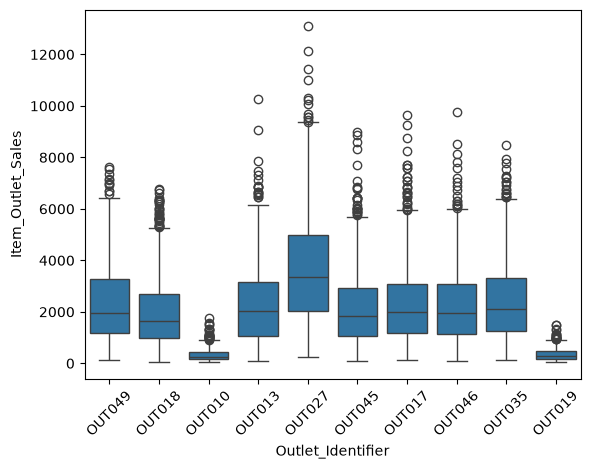

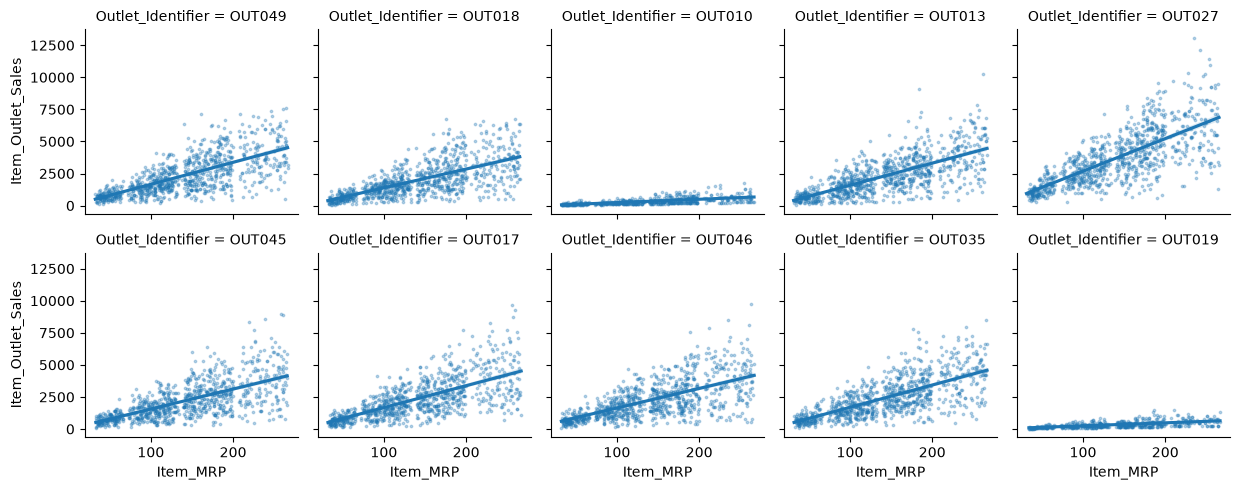

In [18]:
sns.boxplot(x='Outlet_Identifier', y='Item_Outlet_Sales', data=df)
plt.xticks(rotation=45)
plt.show()

# Every outlet has its own level of sales.

sns.lmplot(x='Item_MRP', y='Item_Outlet_Sales', col='Outlet_Identifier', col_wrap=5, data=df,
           scatter_kws={'s': 3, 'alpha': 0.3}, height=2.5)
plt.savefig(root + '/outputs/figures/line_per_outlet.png', dpi=120, bbox_inches='tight')
plt.show()

# Inside each outlet, sales rise in a straight line with Item_MRP. The slope differs by outlet.

In [19]:
# 10. Outlet_Establishment_Year

print(df['Outlet_Establishment_Year'].value_counts().sort_index())
print(df['Outlet_Establishment_Year'].value_counts().sort_index() / len(df) * 100)
print(df.groupby('Outlet_Establishment_Year')['Outlet_Identifier'].unique())

# The year is only a label for the outlet. OUT019 and OUT027 share 1985 but sell very differently.

print('Correlation with sales:', df['Outlet_Establishment_Year'].corr(df['Item_Outlet_Sales']))

# Real but too weak to help.

Outlet_Establishment_Year
1985    1463
1987     932
1997     930
1998     555
1999     930
2002     929
2004     930
2007     926
2009     928
Name: count, dtype: int64
Outlet_Establishment_Year
1985    17.165317
1987    10.935117
1997    10.911651
1998     6.511792
1999    10.911651
2002    10.899918
2004    10.911651
2007    10.864719
2009    10.888185
Name: count, dtype: float64
Outlet_Establishment_Year
1985    [OUT027, OUT019]
1987            [OUT013]
1997            [OUT046]
1998            [OUT010]
1999            [OUT049]
2002            [OUT045]
2004            [OUT035]
2007            [OUT017]
2009            [OUT018]
Name: Outlet_Identifier, dtype: object
Correlation with sales: -0.04913497044082091


In [20]:
# 11. Outlet_Size

print(df['Outlet_Size'].value_counts(dropna=False))
print(df['Outlet_Size'].value_counts(dropna=False) / len(df) * 100)
print(df.loc[df['Outlet_Size'].isnull(), 'Outlet_Identifier'].value_counts())

# The size is missing for 3 whole outlets, not for random rows.

df['Outlet_Size'] = df['Outlet_Size'].fillna(df['Outlet_Size'].mode()[0])
print('Missing after filling:', df['Outlet_Size'].isnull().sum())
print(df.groupby('Outlet_Size')['Item_Outlet_Sales'].mean())

# Filled with the mode, only for tidiness. The outlet identifier already identifies each store.

Outlet_Size
Medium    2793
NaN       2410
Small     2388
High       932
Name: count, dtype: int64
Outlet_Size
Medium    32.770151
NaN       28.276428
Small     28.018303
High      10.935117
Name: count, dtype: float64
Outlet_Identifier
OUT045    929
OUT017    926
OUT010    555
Name: count, dtype: int64
Missing after filling: 0
Outlet_Size
High      2298.995256
Medium    2283.730470
Small     1912.149161
Name: Item_Outlet_Sales, dtype: float64


In [21]:
# 12. Outlet_Location_Type

print(df['Outlet_Location_Type'].value_counts())
print(df['Outlet_Location_Type'].value_counts() / len(df) * 100)
print(df.groupby('Outlet_Location_Type')['Item_Outlet_Sales'].mean())

Outlet_Location_Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64
Outlet_Location_Type
Tier 3    39.305409
Tier 2    32.676288
Tier 1    28.018303
Name: count, dtype: float64
Outlet_Location_Type
Tier 1    1876.909159
Tier 2    2323.990559
Tier 3    2279.627651
Name: Item_Outlet_Sales, dtype: float64


In [22]:
# 13. Outlet_Type

print(df['Outlet_Type'].value_counts())
pct = df['Outlet_Type'].value_counts() / len(df) * 100
print(pct)
print('Biggest outlet type:', pct.index[0], '=', round(pct.iloc[0], 2), '% of rows')

avg = df.groupby('Outlet_Type')['Item_Outlet_Sales'].mean()
print(avg)
print('Type1 sells', round(avg['Supermarket Type1'] / avg['Grocery Store'], 1), 'times more than a Grocery Store on average')

# Grocery stores sell far less than supermarkets, and Type3 sells the most.

# t-test: do grocery stores sell less than Supermarket Type1?
# H0: same average sales, H1: different.
grocery = df[df['Outlet_Type'] == 'Grocery Store']['Item_Outlet_Sales']
super1 = df[df['Outlet_Type'] == 'Supermarket Type1']['Item_Outlet_Sales']

print('Grocery mean:', grocery.mean())
print('Supermarket Type1 mean:', super1.mean())

t, p = stats.ttest_ind(grocery, super1)
print('t =', t, ' p-value =', p)
print('Reject H0: grocery stores really sell less' if p < 0.05 else 'Cannot reject H0')

# The p-value is far below 0.05, so outlets must be treated separately.

Outlet_Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64
Outlet_Type
Supermarket Type1    65.434706
Grocery Store        12.706793
Supermarket Type3    10.970316
Supermarket Type2    10.888185
Name: count, dtype: float64
Biggest outlet type: Supermarket Type1 = 65.43 % of rows
Outlet_Type
Grocery Store         339.828500
Supermarket Type1    2316.181148
Supermarket Type2    1995.498739
Supermarket Type3    3694.038558
Name: Item_Outlet_Sales, dtype: float64
Type1 sells 6.8 times more than a Grocery Store on average
Grocery mean: 339.8285004616805
Supermarket Type1 mean: 2316.181148108302
t = -42.777859363653086  p-value = 0.0
Reject H0: grocery stores really sell less


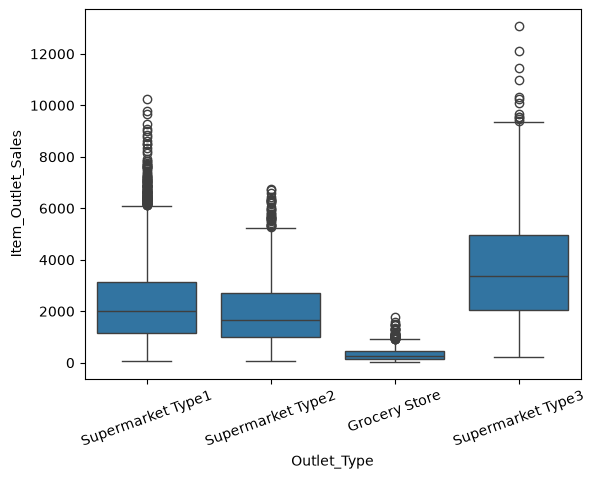

In [23]:
sns.boxplot(x='Outlet_Type', y='Item_Outlet_Sales', data=df)
plt.xticks(rotation=20)
plt.savefig(root + '/outputs/figures/sales_by_outlet_type.png', dpi=120, bbox_inches='tight')
plt.show()

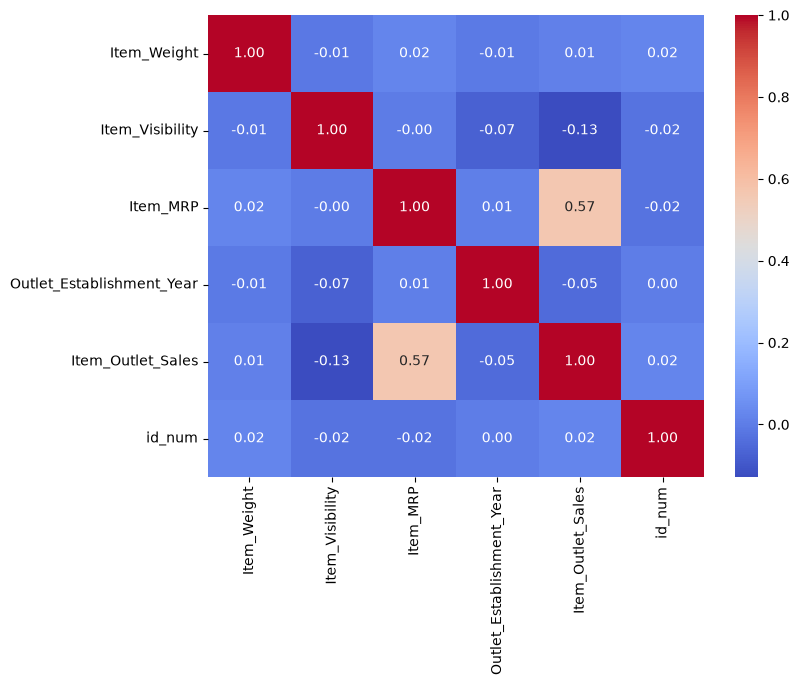

Item_MRP                     r =  0.568   p-value = 0.0000 -> reject H0 (linked)
Item_Weight                  r =  0.012   p-value = 0.2863 -> cannot reject H0 (no evidence of a link)
Item_Visibility              r = -0.129   p-value = 0.0000 -> reject H0 (linked)
Outlet_Establishment_Year    r = -0.049   p-value = 0.0000 -> reject H0 (linked)


In [24]:
# 14. Relationships between columns

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

# Only Item_MRP has a clear link with sales.

# Pearson correlation with sales: H0 no linear relationship, H1 there is one. Reject H0 if p-value < 0.05.
for col in ['Item_MRP', 'Item_Weight', 'Item_Visibility', 'Outlet_Establishment_Year']:
    r, p = stats.pearsonr(df[col], df['Item_Outlet_Sales'])
    print(f"{col:28s} r = {r:6.3f}   p-value = {p:.4f}", '-> reject H0 (linked)' if p < 0.05 else '-> cannot reject H0 (no evidence of a link)')

# Item_MRP (r = 0.57) is clearly linked. Weight is not (p = 0.29). Visibility and year are real but weak.

In [25]:
# 15. A quick model: the average for everyone vs one line per outlet (80% learn, 20% check, RMSE)

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

tr, va = train_test_split(df, test_size=0.2, random_state=42)

def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

# model 1: the average for everyone
print('Average only:', rmse(va['Item_Outlet_Sales'], tr['Item_Outlet_Sales'].mean()))

# model 2: one line per outlet
va = va.copy()
va['pred'] = 0.0
for outlet in tr['Outlet_Identifier'].unique():
    a = tr[tr['Outlet_Identifier'] == outlet]
    b = va['Outlet_Identifier'] == outlet
    line = LinearRegression().fit(a[['Item_MRP']], a['Item_Outlet_Sales'])
    va.loc[b, 'pred'] = line.predict(va.loc[b, ['Item_MRP']])

print('Line per outlet:', rmse(va['Item_Outlet_Sales'], va['pred']))
print('Error cut by', round((1 - rmse(va['Item_Outlet_Sales'], va['pred']) / rmse(va['Item_Outlet_Sales'], tr['Item_Outlet_Sales'].mean())) * 100, 1), '%')

Average only: 1651.989750472933
Line per outlet: 1014.7638762142487
Error cut by 38.6 %


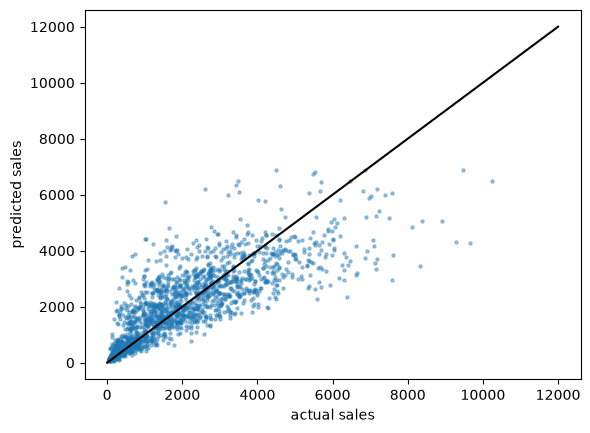

In [26]:
plt.scatter(va['Item_Outlet_Sales'], va['pred'], s=5, alpha=0.4)
plt.plot([0, 12000], [0, 12000], color='black')
plt.xlabel('actual sales')
plt.ylabel('predicted sales')
plt.savefig(root + '/outputs/figures/actual_vs_predicted.png', dpi=120, bbox_inches='tight')
plt.show()

# Points follow the line but spread out for big sales: much of the sales is random.

In [27]:
# 16. Hidden pattern: sales = units x price
# If sales are whole units times a price, sales / 0.6658 should be whole numbers.

STEP = 0.6658
df['steps'] = df['Item_Outlet_Sales'] / STEP

# how far is each value from a whole number?
gap = (df['steps'] - df['steps'].round()).abs()
print('largest gap from a whole number:', gap.max())
print('percent of rows within 0.01 of a whole number:', (gap < 0.01).sum() / len(df) * 100)

# All 8523 sales are whole multiples of 0.6658, so sales are units x price.

largest gap from a whole number: 3.637978807091713e-12
percent of rows within 0.01 of a whole number: 100.0


In [28]:
# one item sold in 8 outlets: its MRP changes, its sales stay on a few steps
df[df['Item_Identifier'] == 'FDA15'][['Outlet_Identifier', 'Item_MRP', 'Item_Outlet_Sales', 'steps']]

,Outlet_Identifier,Item_MRP,Item_Outlet_Sales,steps
0,OUT049,249.8092,3735.1380,5610.0
831,OUT045,250.2092,5976.2208,8976.0
2599,OUT035,248.5092,6474.2392,9724.0
2643,OUT018,249.6092,5976.2208,8976.0
4874,OUT010,248.9092,498.0184,748.0
5413,OUT013,250.6092,6474.2392,9724.0
6696,OUT027,249.5092,6474.2392,9724.0
7543,OUT017,248.8092,5976.2208,8976.0


items with a recovered price: 1479 of 1555
percent of validation rows whose item has a price: 95.77712609970675
count    6.447000e+03
mean     2.745463e-03
std      1.186454e+00
min     -2.000000e+00
25%     -1.000000e+00
50%      7.105427e-15
75%      1.100000e+00
max      2.000000e+00
dtype: float64
largest gap of units from a whole number: 7.105427357601002e-15
Outlet_Type
Grocery Store         2.444717
Supermarket Type1    16.416667
Supermarket Type2    13.974719
Supermarket Type3    26.700416
Name: units, dtype: float64


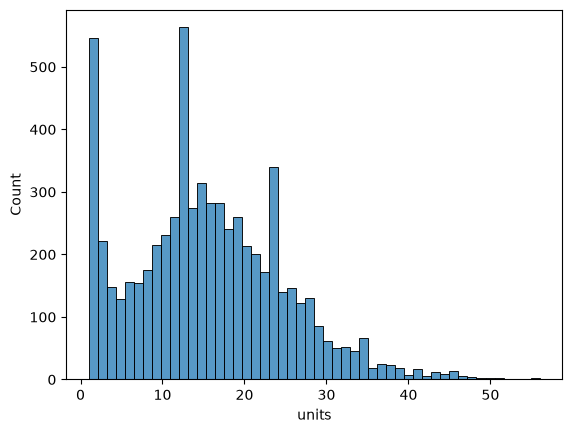

In [29]:
# recover each item's real price from the learning rows: on the 0.6658 grid, within 2 of every MRP, dividing every sales step
def item_prices(d, noise=2.0):
    prices = {}
    for item, g in d.groupby('Item_Identifier'):
        k = np.round(g['Item_Outlet_Sales'] / STEP).astype(int).to_numpy()
        lo = max(int(np.ceil((g['Item_MRP'].max() - noise) / STEP)), 1)
        hi = int(np.floor((g['Item_MRP'].min() + noise) / STEP))
        fits = [q for q in range(lo, hi + 1) if np.all(k % q == 0)]
        if fits:   # if several fit, take the one nearest the average MRP
            prices[item] = min(fits, key=lambda q: abs(q * STEP - g['Item_MRP'].mean())) * STEP
    return prices

prices = item_prices(tr)
print('items with a recovered price:', len(prices), 'of', tr['Item_Identifier'].nunique())
print('percent of validation rows whose item has a price:', va['Item_Identifier'].isin(prices).sum() / len(va) * 100)

error = tr['Item_MRP'] - tr['Item_Identifier'].map(prices)
print(error.describe())

# MRP minus the real price runs from -2 to +2 with mean 0, like random noise.

# units sold = sales / real price
tr = tr.copy()
tr['units'] = tr['Item_Outlet_Sales'] / tr['Item_Identifier'].map(prices)
print('largest gap of units from a whole number:', (tr['units'] - tr['units'].round()).abs().max())
print(tr.groupby('Outlet_Type')['units'].mean())

sns.histplot(tr['units'].dropna(), bins=50)
plt.show()

# Units are whole numbers (a count) and skewed to the right. Grocery stores sell only a few units per row.

In [30]:
# line per outlet with MRP vs with the real price
def line_per_outlet(price_of):
    pred = pd.Series(0.0, index=va.index)
    for outlet in tr['Outlet_Identifier'].unique():
        a = tr[tr['Outlet_Identifier'] == outlet]
        b = va['Outlet_Identifier'] == outlet
        line = LinearRegression().fit(price_of(a).to_frame('price'), a['Item_Outlet_Sales'])
        pred[b] = line.predict(price_of(va[b]).to_frame('price'))
    return rmse(va['Item_Outlet_Sales'], pred)

real_price = lambda d: d['Item_Identifier'].map(prices).fillna(d['Item_MRP'])

print('with Item_MRP:   ', line_per_outlet(lambda d: d['Item_MRP']))
print('with real price: ', line_per_outlet(real_price))
print('RMSE change from using the real price:', round(line_per_outlet(real_price) - line_per_outlet(lambda d: d['Item_MRP']), 2))

# RMSE is almost the same, so a straight line cannot use the cleaner price.

with Item_MRP:    1014.7638762142487
with real price:  1015.1394184390234
RMSE change from using the real price: 0.38
